利用 Seaborn 绘制了图像降维后特征的核密度图和箱线图。从图中可以看出，正负样本在主要特征分布上存在一定重叠，证明k-means的分类能力不足，需要Svm 深度学习

未找到中间文件，使用模拟数据测试...


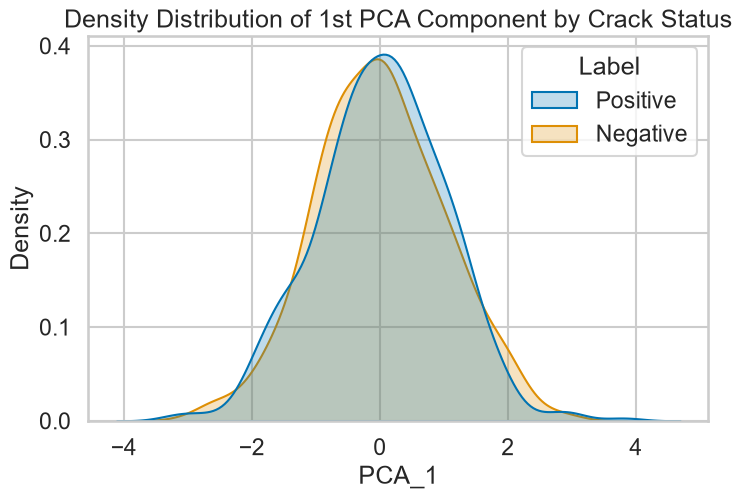

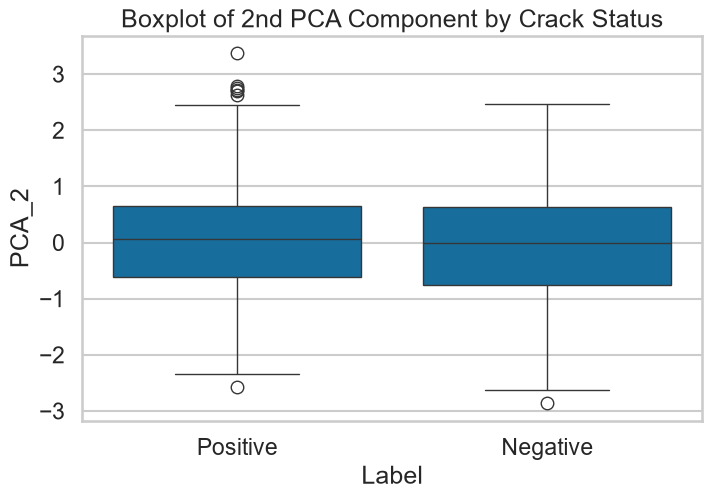

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ==================== 1. 加载数据 ====================
# 从 K-Means 中间结果加载
try:
    # 加载 PCA 降维后的特征
    pca_images = np.load('pca_images.npy')
    labels = pd.read_csv('labels.csv')['label'].tolist()
except:
    # 如果没有保存，使用模拟数据测试
    print('未找到中间文件，使用模拟数据测试...')
    pca_images = np.random.randn(1000, 50)
    labels = np.random.choice(['Positive', 'Negative'], 1000)

# ==================== 2. 可视化 ====================
# 提取信息 可视化
df_pca = pd.DataFrame({
    'PCA_1': pca_images[:, 0],
    'PCA_2': pca_images[:, 1],
    'Label': labels
})

sns.set_theme(context="talk", style="whitegrid", palette="colorblind")

# 核密度估计图
fig, ax = plt.subplots(figsize=(8, 5))
sns.kdeplot(data=df_pca, x="PCA_1", hue="Label", fill=True, common_norm=False, ax=ax)
ax.set_title("Density Distribution of 1st PCA Component by Crack Status")
plt.show()

# 箱线图
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df_pca, x="Label", y="PCA_2", ax=ax)
ax.set_title("Boxplot of 2nd PCA Component by Crack Status")
plt.show()

5折法的统计学优势

In [7]:
import numpy as np
from scipy import stats

# 5折法
cv_accuracies = np.array([5次accuracy数据])

# 均值和标准误
mean_acc = np.mean(cv_accuracies)
se_acc = np.std(cv_accuracies, ddof=1) / np.sqrt(len(cv_accuracies))

# 95% 置信区间
ci_95 = stats.t.interval(0.95, df=len(cv_accuracies)-1, loc=mean_acc, scale=se_acc)

#输出
print(f"5-Fold CV Mean Accuracy: {mean_acc:.4f}")
print(f"Standard Error (SE): {se_acc:.4f}")
print(f"95% Confidence Interval: ({ci_95[0]:.4f}, {ci_95[1]:.4f})")

SyntaxError: invalid syntax. Perhaps you forgot a comma? (3552478967.py, line 5)

统计学模型聚类能力

In [ ]:
df_pca['Cluster_Label'] = cluster_labels

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# 真实的物理标签
sns.scatterplot(data=df_pca, x="PCA_1", y="PCA_2", hue="Label", alpha=0.7, ax=axes[0])
axes[0].set_title("Ground Truth (Cracked vs Non-cracked)")

# K-Means 聚类结果
sns.scatterplot(data=df_pca, x="PCA_1", y="PCA_2", hue="Cluster_Label", palette="viridis", alpha=0.7, ax=axes[1])
axes[1].set_title("K-Means Clustering Result")

plt.tight_layout()
plt.show()

经济性对比，模型优劣的另一个指标

In [ ]:
#需要一个svm混淆矩阵
conf_matrix_svm = np.array([[数据],

cost_FP = 50   # 误检复核人工成本
cost_FN = 1000 # 漏检导致设备损坏预期成本

# 计算不同模型的预期商业损失
conf_matrix_cnn = np.array([[],   # CNN数据
                            []])

svm_loss = conf_matrix_svm[0,1]*cost_FP + conf_matrix_svm[1,0]*cost_FN
cnn_loss = conf_matrix_cnn[0,1]*cost_FP + conf_matrix_cnn[1,0]*cost_FN

#可视化
df_cost = pd.DataFrame({
    'Model': ['SVM', 'CNN'],
    'Expected Financial Loss (RMB)': [svm_loss, cnn_loss]
})

fig, ax = plt.subplots(figsize=(6, 5))
sns.barplot(data=df_cost, x='Model', y='Expected Financial Loss (RMB)', palette=['#B7791F', '#006A8E'], ax=ax)
ax.set_title("Decision Impact: Expected Cost by Model")
plt.show()